### Imports

In [2]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.visualization import plot_histogram
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
from scipy.optimize import minimize
import numpy as np

### Building the cost Hamiltonian

In [3]:
graph = [("ZZ", [0,1], 1),
         ("ZZ", [0,2], 1),
         ("ZZ", [1,2], 1),
         ("ZZ", [1,3], 1),
         ("ZZ", [2,4], 1),
         ("ZZ", [3,4], 1)]
H_c = SparsePauliOp.from_sparse_list(graph, num_qubits = 5)

### Exhaustive search : brute-force method

In [5]:
states_and_values = []

min_value = 6

for i in range(2 ** 5):
  state = Statevector.from_int(i, dims=2**5)

  exp_value = state.expectation_value(H_c)

  states_and_values.append((state, exp_value))

  if exp_value < min_value:
    min_value = exp_value

print("The minimum expected value is:", min_value)

for state, exp_value in states_and_values:
  if exp_value == min_value:
    print(state)

The minimum expected value is: (-4+0j)
Statevector([0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 1.+0.j, 0.+0.j,
             0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j],
            dims=(2, 2, 2, 2, 2))
Statevector([0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 1.+0.j,
             0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j],
            dims=(2, 2, 2, 2, 2))
Statevector([0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 1.+0.j, 0.+0.j, 0.+0.j,
             0.+0.j, 0.+0.j, 0.+0.j, 0.+0.

The states resulting from this code are ∣01100⟩, ∣01101⟩, ∣10010⟩, and ∣10011⟩ (read from right to left), and after verification, they do indeed represent 5-cuts.

Furthermore, it makes sense for this graph to have a minimum expected value of −4, since it is not possible to cut more than 5 edges in the graph. The 3 edges ABC cannot all be cut without cutting an edge twice or ending up inside the graph.

So, we cut 5 of the 6 edges, giving $C = 5 \times (-1) + 1 \times (+1) = -4$.

### Deriving the cost-layer gate decomposition

$U_c = \exp(-i\gamma[k]H_c)$. For a pair of qubits $(i,j)$, $H_c = Z_iZ_j$, and $Z_iZ_j = \operatorname{diag}(1,-1,-1,1)$.

Since $Z_iZ_j$ is diagonal, we can apply $\exp(-i\gamma[k]x)$ to its elements. Therefore:

$$
U_c(\gamma[k]) =
\begin{pmatrix}
e^{-i\gamma[k]} & 0 & 0 & 0 \\
0 & e^{i\gamma[k]} & 0 & 0 \\
0 & 0 & e^{i\gamma[k]} & 0 \\
0 & 0 & 0 & e^{-i\gamma[k]}
\end{pmatrix}
$$

On doit calculer CNOT(I x Rz(2γ))CNOT

A = CNOT(I x Rz(2γ)) = [[exp(-iγ), 0, 0, 0], [0, exp(iγ), 0, 0], [0, 0, 0, exp(-iγ)], [0, 0, exp(iγ), 0]]

Puis A*CNOT = [[exp(-iγ), 0, 0, 0], [0, exp(iγ), 0, 0], [0, 0, exp(iγ), 0], [0, 0, 0, exp(-iγ)]]

Donc on a bien Uc = CNOT(I x Rz(2γ))CNOT

We need to compute $\mathrm{CNOT}\,(I \otimes R_z(2\gamma))\,\mathrm{CNOT}$.

$$
A = \mathrm{CNOT}\,(I \otimes R_z(2\gamma)) =
\begin{pmatrix}
e^{-i\gamma} & 0 & 0 & 0 \\
0 & e^{i\gamma} & 0 & 0 \\
0 & 0 & 0 & e^{i\gamma} \\
0 & 0 & e^{-i\gamma} & 0
\end{pmatrix}
$$

Then
$$
A \cdot \mathrm{CNOT} =
\begin{pmatrix}
e^{-i\gamma} & 0 & 0 & 0 \\
0 & e^{i\gamma} & 0 & 0 \\
0 & 0 & e^{i\gamma} & 0 \\
0 & 0 & 0 & e^{-i\gamma}
\end{pmatrix}
$$

Hence, we indeed have $U_C = \mathrm{CNOT}\,(I \otimes R_z(2\gamma))\,\mathrm{CNOT}$.

### Building the QAOA ansatz circuit

In [140]:
ansatz = QAOAAnsatz(H_c, reps = 2)
ansatz.decompose(reps = 2).draw()

┌────────────┐                          ┌────────────┐             »
q_0: ┤ U(π/2,0,π) ├─■────────────■───────────┤ Rx(2*β[0]) ├─────────────»
     ├────────────┤ │ZZ(2*γ[0])  │           └────────────┘             »
q_1: ┤ U(π/2,0,π) ├─■────────────┼────────────■─────────────■───────────»
     ├────────────┤              │ZZ(2*γ[0])  │ZZ(2*γ[0])   │           »
q_2: ┤ U(π/2,0,π) ├──────────────■────────────■─────────────┼───────────»
     ├────────────┤                                         │ZZ(2*γ[0]) »
q_3: ┤ U(π/2,0,π) ├─────────────────────────────────────────■───────────»
     ├────────────┤                                                     »
q_4: ┤ U(π/2,0,π) ├─────────────────────────────────────────────────────»
     └────────────┘                                                     »
«                                               ┌────────────┐             »
«q_0: ───────────────■─────────────■────────────┤ Rx(2*β[1]) ├─────────────»
«     ┌────────────┐ │ZZ(2*γ[1])   │            └────────────┘             »
«q_1: ┤ Rx(2*β[0]) ├─■─────────────┼─────────────■─────────────■───────────»
«     └────────────┘┌────────────┐ │ZZ(2*γ[1])   │ZZ(2*γ[1])   │           »
«q_2: ─■────────────┤ Rx(2*β[0]) ├─■─────────────■─────────────┼───────────»
«      │            └────────────┘┌────────────┐               │ZZ(2*γ[1]) »
«q_3: ─┼─────────────■────────────┤ Rx(2*β[0]) ├───────────────■───────────»
«      │ZZ(2*γ[0])   │ZZ(2*γ[0])  ├────────────┤                           »
«q_4: ─■─────────────■────────────┤ Rx(2*β[0]) ├───────────────────────────»
«                                 └────────────┘                           »
«                                               
«q_0: ──────────────────────────────────────────
«     ┌────────────┐                            
«q_1: ┤ Rx(2*β[1]) ├────────────────────────────
«     └────────────┘┌────────────┐              
«q_2: ─■────────────┤ Rx(2*β[1]) ├──────────────
«      │            └────────────┘┌────────────┐
«q_3: ─┼─────────────■────────────┤ Rx(2*β[1]) ├
«      │ZZ(2*γ[1])   │ZZ(2*γ[1])  ├────────────┤
«q_4: ─■─────────────■────────────┤ Rx(2*β[1]) ├
«                                 └────────────┘

### Defining the cost function (expectation value)

In [ ]:
def cost(parameters, ansatz_circuit, H_c):
  estimator = StatevectorEstimator(default_precision=1e-2)
  job = estimator.run([(ansatz_circuit, H_c, parameters)])

  expectation_value_empirical = job.result()[0].data.evs

  return expectation_value_empirical

print(cost([1, 1, 1, 1], ansatz, H_c))

0.17980960569701704


### Initializing the circuit parameters

In [142]:
p = 2

x0 = np.random.rand(2 * p) * 2 * np.pi

print(x0)

[4.0706935  5.50590032 1.95956952 3.67404679]


### Classical optimization with the best classical function ever

In [143]:
res = minimize(fun=cost, x0=x0, args=(ansatz, H_c), method="COBYLA")

In [144]:
print(res)

 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: -2.3642725003372034
       x: [ 5.056e+00  6.446e+00  2.812e+00  4.591e+00]
    nfev: 47
   maxcv: 0.0


In [146]:
mean = 0

for i in range(10):
  res = minimize(fun=cost, x0=x0, args=(ansatz, H_c), method="COBYLA")
  x0 = np.random.rand(2 * p) * 2 * np.pi
  mean += res.fun
  print("res: ", res.x)
  print(res.fun)

mean /= 10

print(mean)

res:  [1.30029668 5.0681125  1.60608053 1.22689776]
-2.2413260361756855
res:  [1.7842639  1.36457632 2.83943856 6.98326012]
-2.7662064346345754
res:  [6.0711582  5.39341875 4.19233468 3.13085764]
-1.0099115080706225
res:  [3.34137885 2.89604845 2.96250026 0.47860556]
-2.5827424972674686
res:  [2.63520203 2.88013259 3.41140224 3.6735831 ]
-3.2143948133808533
res:  [5.9390711  1.57379972 3.50019984 1.77232144]
-2.2029075509161853
res:  [2.08752668 3.46404623 2.86316461 2.64392041]
-3.261996912752769
res:  [1.75846449 4.39599709 2.65259043 4.06549151]
-2.7949977859017276
res:  [3.36209173 5.51453498 5.40915655 2.98727412]
-0.8809588952541142
res:  [2.04506397 5.00394031 2.83697847 5.71720895]
-3.1911872224591673
-2.414662965681317


### Sampling and analyzing the results

[2.08752668 3.46404623 2.86316461 2.64392041]



/usr/local/lib/python3.12/dist-packages/scipy/sparse/linalg/_dsolve/linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve
/usr/local/lib/python3.12/dist-packages/scipy/sparse/linalg/_matfuncs.py:707: SparseEfficiencyWarning: spsolve is more efficient when sparse b is in the CSC matrix format
  return spsolve(Q, P)
/usr/local/lib/python3.12/dist-packages/scipy/sparse/_index.py:168: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


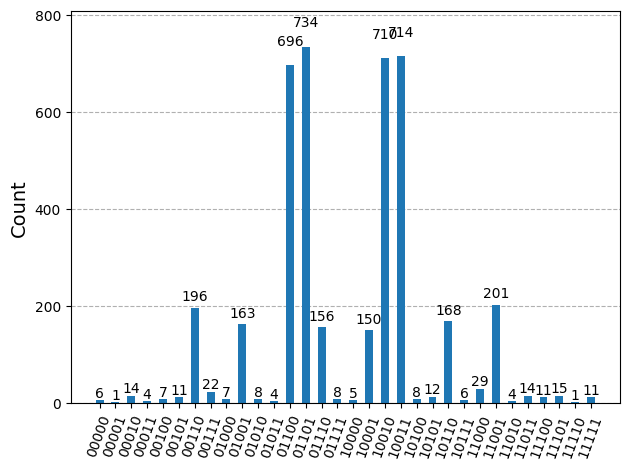

In [152]:
x = np.array([2.08752668, 3.46404623, 2.86316461, 2.64392041])
print(x, end="\n\n")

ansatz = QAOAAnsatz(H_c, reps = 2)

measure_qc = QuantumCircuit(5, 5)
measure_qc.measure(range(5), range(5))

ansatz = ansatz.compose(measure_qc)

job = StatevectorSampler().run([(ansatz, x)], shots=4096)
result = job.result()
data = result[0].data
counts = data.c.get_counts()

plot_histogram(counts)

On retrouve bien les 4 state_vectors solutions.

In [153]:
print("Resulting states :")
for state, n in counts.items():
  if n > 450:
    print(state)

Resulting states :
01101
10011
01100
10010


### More questions

Qu'est ce qui change dans le circuit QAOA si on veut faire le problème de weighted MaxCut ?

La fonction de coût est modifiée. On ne cherche plus seulement à couper le maximum d'arêtes mais à maximiser la somme du poids des arêtes. Donc C(z_i, z_j, p_ij) = ∑ z_i*z_j + ∑ p_ij

Cela ajoute donc un 2ème hamiltonien H_mixer qu'on ne prenait pas en compte dans le MaxCut classique.

Il faut donc encoder ces poids lors de l'initialisation dans des qubits supplémentaires dans le circuit.